Part 1: Linear Regression

Introduction

The medical aid scheme wants to develop a data-driven method for estimating customer medical aid costs according to demographic, lifestyle and geographic characteristics. The proposed solution is a Linear Regression model that predicts individual medical insurance charges using age, sex, Body Mass Index (BMI), number of children, smoking status and geographical region.

Evaluate the Dataset for Suitability

Dataset Description

| Variable | Type        | Description              | Role      |
| -------- | ----------- | ------------------------ | --------- |
| age      | Numerical   | Age of beneficiary       | Predictor |
| sex      | Categorical | Male/female              | Predictor |
| bmi      | Numerical   | Body Mass Index          | Predictor |
| children | Numerical   | Number of dependants     | Predictor |
| smoker   | Categorical | Smoking status           | Predictor |
| region   | Categorical | Residential region       | Predictor |
| charges  | Numerical   | Individual medical costs | Target    |


The dataset is appropriate for a Linear Regression proof of concept because the dependent variable, charges, is continuous numerical data. The predictor variables contain both numerical and categorical information, which can be converted into numerical representations through one-hot encoding.

The dataset contains sufficient observations for an initial machine-learning model, with 1,338 rows.

Import the required libraries

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

Load the insurance dataset

In [3]:

df = pd.read_csv("insurance.csv")

# Display the first five records
print(df.head())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


The dataset supplied by Kaggle contains 1,338 observations and the seven variables described above.

Examine Dataset

In [4]:
# Display the dimensions of the dataset

print("Dataset shape:", df.shape)

# Display information about columns and data types

print(df.info())

# Display descriptive statistics

print(df.describe())

Dataset shape: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2

Check for Missing Values

In [5]:
# Count missing values in each column

print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


As all values are zero, this indicates that there are no missing observations requiring imputation.

Check for Duplicates

In [10]:
# Count duplicate records

print("Number of duplicates:", df.duplicated().sum())

Number of duplicates: 0


Examine Categorical Variables

In [11]:
print(df["sex"].value_counts())
print(df["smoker"].value_counts())
print(df["region"].value_counts())

sex
male      675
female    662
Name: count, dtype: int64
smoker
no     1063
yes     274
Name: count, dtype: int64
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


This determines whether the categorical variables are reasonably distributed.

Distribution of Medical Charges

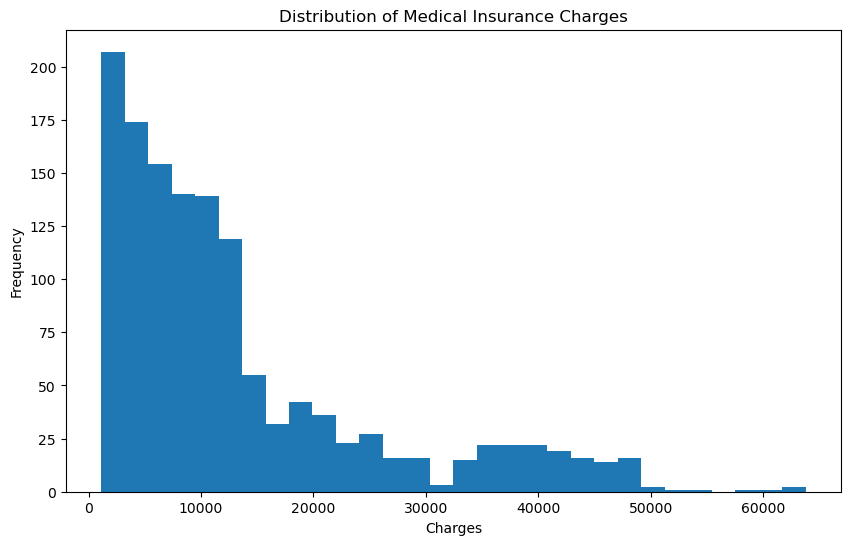

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(df["charges"], bins=30)

plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Charges")
plt.ylabel("Frequency")

plt.show()

The charges distribution is expected to be positively/right skewed. This occurs because a relatively small group of individuals has substantially higher medical costs.

This is important because extreme charges can influence the coefficients of a Linear Regression model.

Age vs Charges

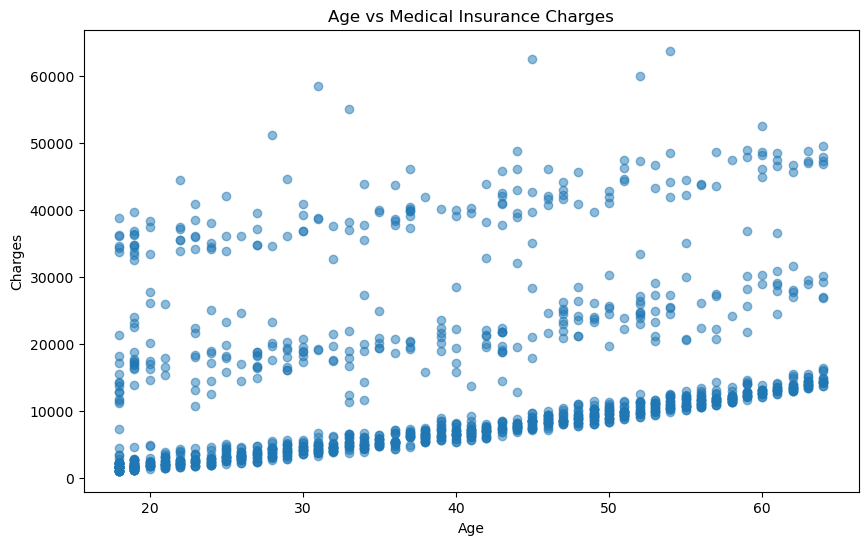

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(df["age"], df["charges"], alpha=0.5)

plt.title("Age vs Medical Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Charges")

plt.show()

The plot should generally indicate that medical charges tend to increase as age increases. However, there will be considerable variation between individuals.

This suggests that age is a potentially useful predictor.

BMI vs Charges

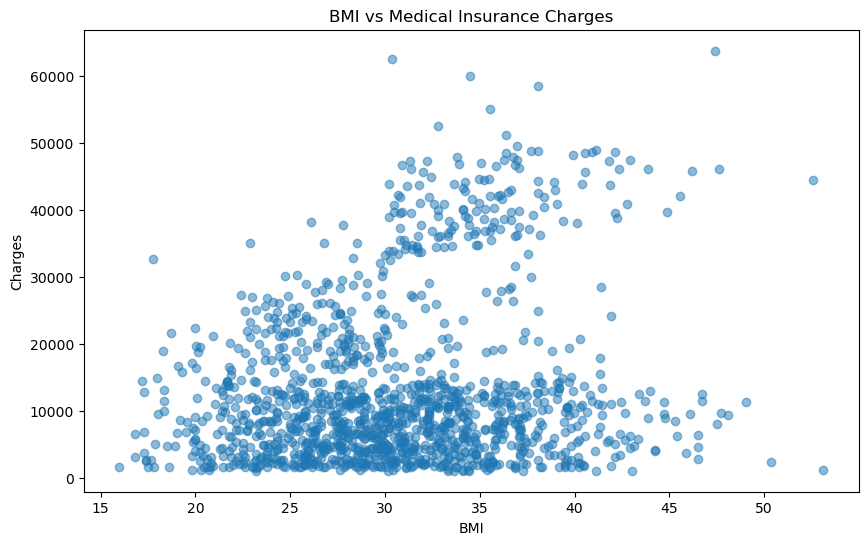

In [14]:
plt.figure(figsize=(10, 6))

plt.scatter(df["bmi"], df["charges"], alpha=0.5)

plt.title("BMI vs Medical Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Charges")

plt.show()

BMI is expected to have a positive relationship with charges, although the relationship is unlikely to be perfectly linear.

Smoking Status vs Charges

<Figure size 800x600 with 0 Axes>

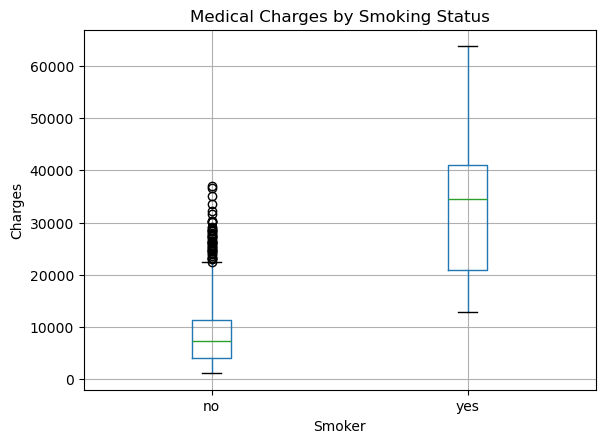

In [15]:
plt.figure(figsize=(8, 6))

df.boxplot(column="charges", by="smoker")

plt.title("Medical Charges by Smoking Status")
plt.suptitle("")
plt.xlabel("Smoker")
plt.ylabel("Charges")

plt.show()

Smoking status is expected to be one of the strongest predictors of insurance charges. Previous analyses of this dataset similarly identify smoking status, age and BMI as important factors affecting charges.

This is particularly important from a business perspective because it demonstrates that lifestyle variables may substantially affect predicted costs.

`Average Charges by Smoking Status

In [16]:
print(
    df.groupby("smoker")["charges"]
      .mean()
      .sort_values(ascending=False)
)

smoker
yes    32050.231832
no      8440.660307
Name: charges, dtype: float64


This allows the organisation to compare the average charges of smokers and non-smokers.

Average Charges by Region

In [17]:
region_charges = (
    df.groupby("region")["charges"]
      .mean()
      .sort_values(ascending=False)
)

print(region_charges)

region
southeast    14735.411438
northeast    13406.384516
northwest    12450.840844
southwest    12346.937377
Name: charges, dtype: float64


This helps determine whether geographical location contributes significantly to differences in charges.

Correlation Analysis

In [18]:
correlation = df[
    ["age", "bmi", "children", "charges"]
].corr()

print(correlation)

               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


A correlation matrix can be visualised:

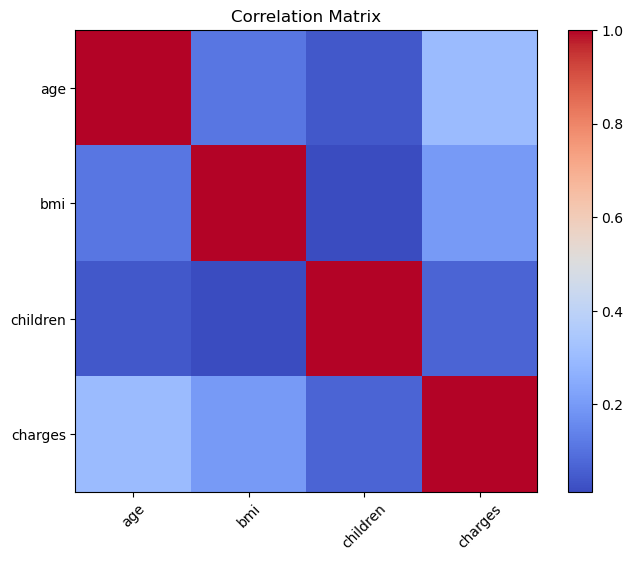

In [19]:
plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm")

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")

plt.show()

Feature Selection and Preparation

In [21]:
X = df.drop("charges", axis=1)

y = df["charges"]

In [22]:
numeric_features = [
    "age",
    "bmi",
    "children"
]

categorical_features = [
    "sex",
    "smoker",
    "region"
]

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(drop="first"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

Train-Test Split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1069
Testing records: 268


This produces an approximately:

80% training set
20% testing set

The testing set is kept separate so that model performance can be assessed using previously unseen observations.

Train the Linear Regression Model

In [25]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Predictions:

In [26]:
y_pred = model.predict(X_test)

Evaluate the Model

In [27]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 4177.045561036313
RMSE: 5956.34289436358
R²: 0.8069287081198017


For this commonly used dataset, a standard one-hot-encoded Linear Regression implementation typically produces an R² in the high-0.7 range on a 20% test split, although the exact results depend on preprocessing and the random train/test split. The important point is to report the values produced by your own execution, rather than copying results from another implementation.

Actual vs Predicted Charges

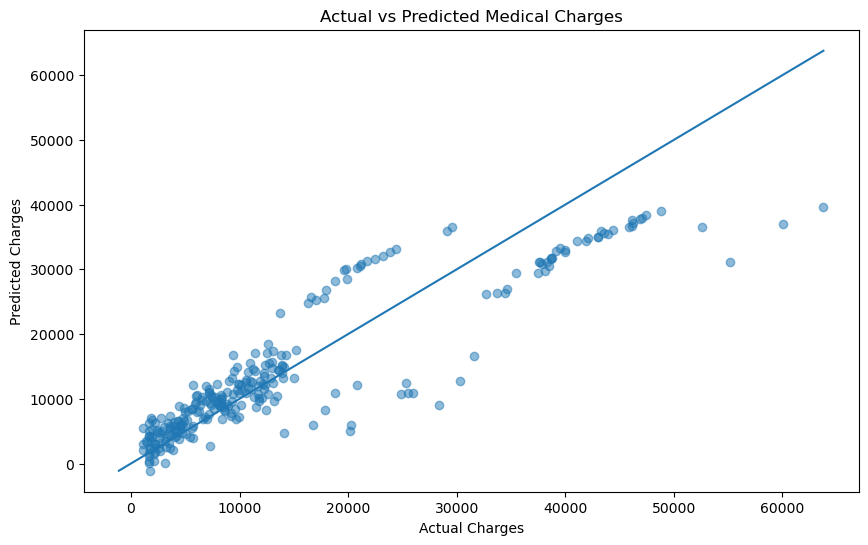

In [28]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")

plt.title("Actual vs Predicted Medical Charges")

# Perfect prediction line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum]
)

plt.show()

If predictions were perfect, all observations would lie directly on the diagonal line.

Points further away from the line represent larger prediction errors.

Residual Analysis

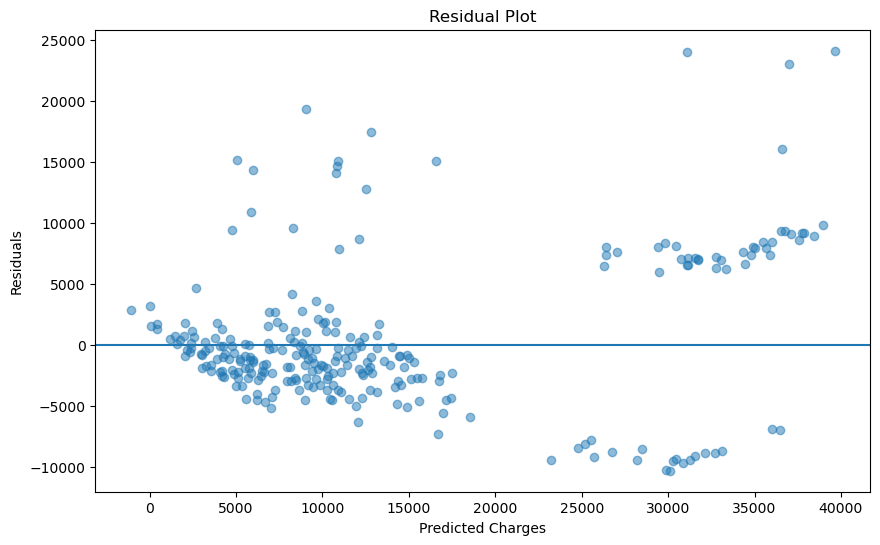

In [29]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))

plt.scatter(y_pred, residuals, alpha=0.5)

plt.axhline(y=0)

plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

The residuals should ideally be distributed relatively randomly around zero.

If the residuals show a clear pattern, this may indicate that Linear Regression does not completely capture the relationship between the predictors and charges.

Retraining the Model

In [33]:
y_log = np.log1p(df["charges"])